## Spatial Model Error Mapping
- V2 is for season length and other statistics calculated from OutputStatsV2.py

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Jupyter's default bbox_inches='tight' on inline figures mis-crops cartopy's
# fixed-aspect GeoAxes (subplot columns get clipped). Disable it so the
# manually-tuned subplots_adjust/colorbar layout below renders as drawn.
get_ipython().run_line_magic('config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")

In [2]:
# Load the CSV data for all six model runs
model_files = {
    's00000000_ghec_v0003': '../outputV2_snotel_sites_v2_s00000000_ghec_v0003.csv',
    's01011010_ghec_v0004': '../outputV2_snotel_sites_v2_s01011010_ghec_v0004.csv',
    's01011010_ghelaps_v0008': '../outputV2_snotel_sites_v2_s01011010_ghelaps_v0008.csv',
    's01011010_gbc_v0005': '../outputV2_snotel_sites_v2_s01011010_gbc_v0005.csv',
    's01011010_ghelaps_veg_v0009': '../outputV2_snotel_sites_v2_s01011010_ghelaps_veg_v0009.csv',
    's01012010_ghelaps_v0011': '../outputV2_snotel_sites_v2_s01012010_ghelaps_v0011.csv',
}
dfs = {name: pd.read_csv(path) for name, path in model_files.items()}


In [3]:
dfs['s01011010_gbc_v0005'].query("site == 'Pepper Creek'")

,site,latitude,longitude,avg_snow_days_snotel,avg_snow_days_model,avg_snow_days_model_all,avg_onset_wydoy_model_all,avg_meltout_wydoy_model_all,n_matched_snow_years,n_snow_years_model,avg_peak_wydoy_snotel,avg_peak_wydoy_model,avg_peak_wydoy_model_all,avg_peak_swe_snotel,avg_peak_swe_model,avg_peak_swe_model_all,n_matched_peak_years,n_peak_years_model
624,Pepper Creek,46.1,-121.96,117.2,13.8,13.8,90.3,117.9,11,11,146.1,105.3,105.3,268.3,35.0,35.0,11,11


In [4]:
# Remove sites where snotel has less than 5 years
dfs = {name: d[d['n_matched_snow_years'] >= 5] for name, d in dfs.items()}

### Snow Days
Compare model snow days to snotel

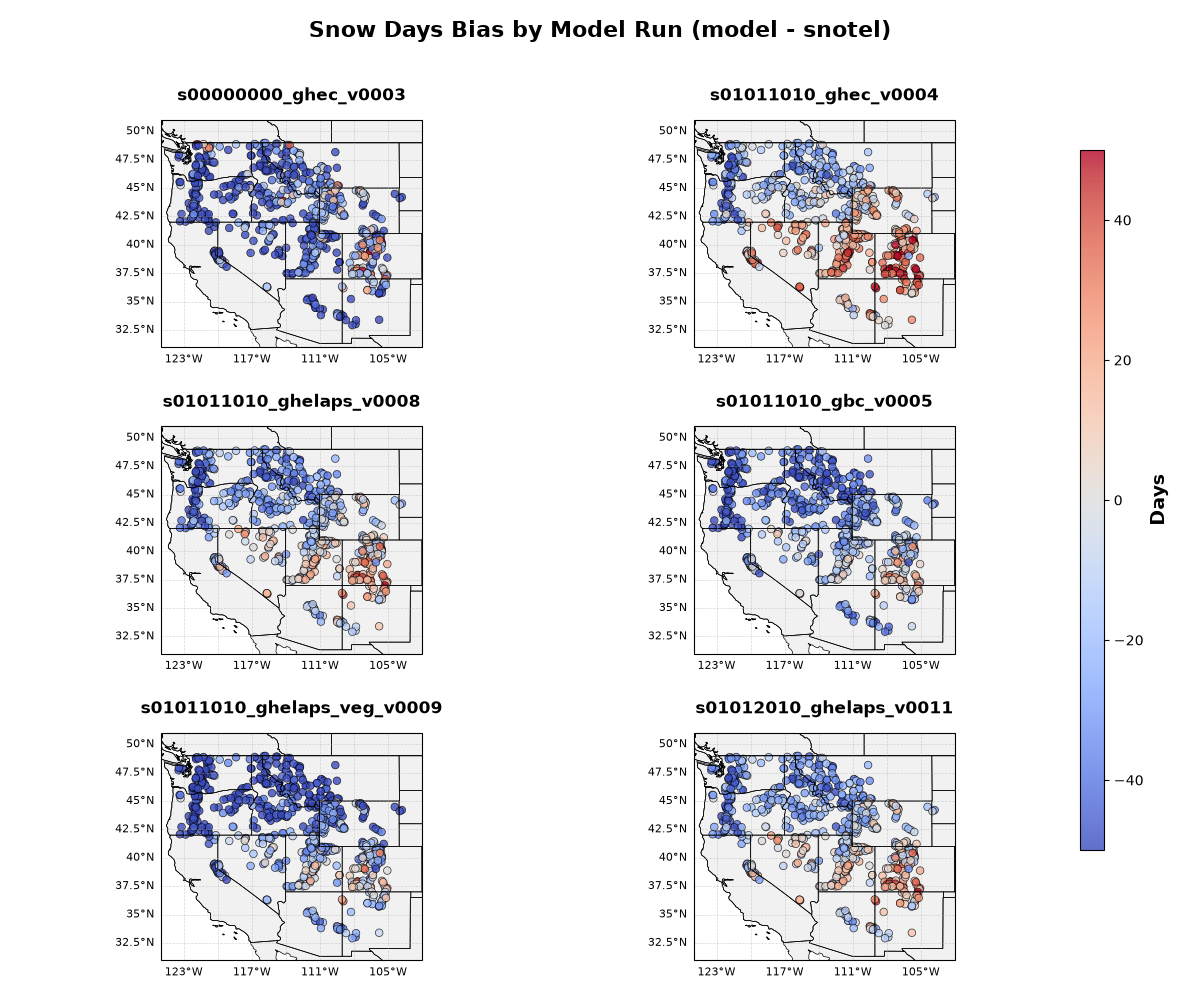

In [5]:
# Snow days map - one subplot per model run
fig, axes = plt.subplots(3, 2, figsize=(12, 10), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(left=0.05, right=0.88, top=0.88, bottom=0.04, wspace=0.15, hspace=0.35)

for ax, (name, model_df) in zip(axes.flat, dfs.items()):
    model_snow_days = model_df[['site', 'latitude', 'longitude', 'avg_snow_days_snotel', 'avg_snow_days_model']].copy()
    model_snow_days['model_snotel_ddays'] = model_snow_days['avg_snow_days_model'] - model_snow_days['avg_snow_days_snotel']

    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(model_snow_days['longitude'], model_snow_days['latitude'],
                         c=model_snow_days['model_snotel_ddays'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-50,
                         vmax=50,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=12, fontweight='bold', y=1.05)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

fig.suptitle('Snow Days Bias by Model Run (model - snotel)', fontsize=16, fontweight='bold')
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Days', fontsize=14, fontweight='bold')
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Analysis
- Each panel looks essentially the same as a bias plot, but ghelaps does have some sites in AZ where bias is positive but snow days are negative.

### Peak SWE

Compare model peak SWE date to snotel, in day of water year (Oct 1 = day 1). `OutputStatsV2.py` computes `avg_peak_wydoy_*` this way (rather than calendar day-of-year) so that a peak occurring in Oct-Dec and one occurring in Jan-Jul are on the same continuous, averaging-safe scale — calendar DOY would otherwise wrap an early-season peak to a large value that isn't comparable to a late-season peak's small one.

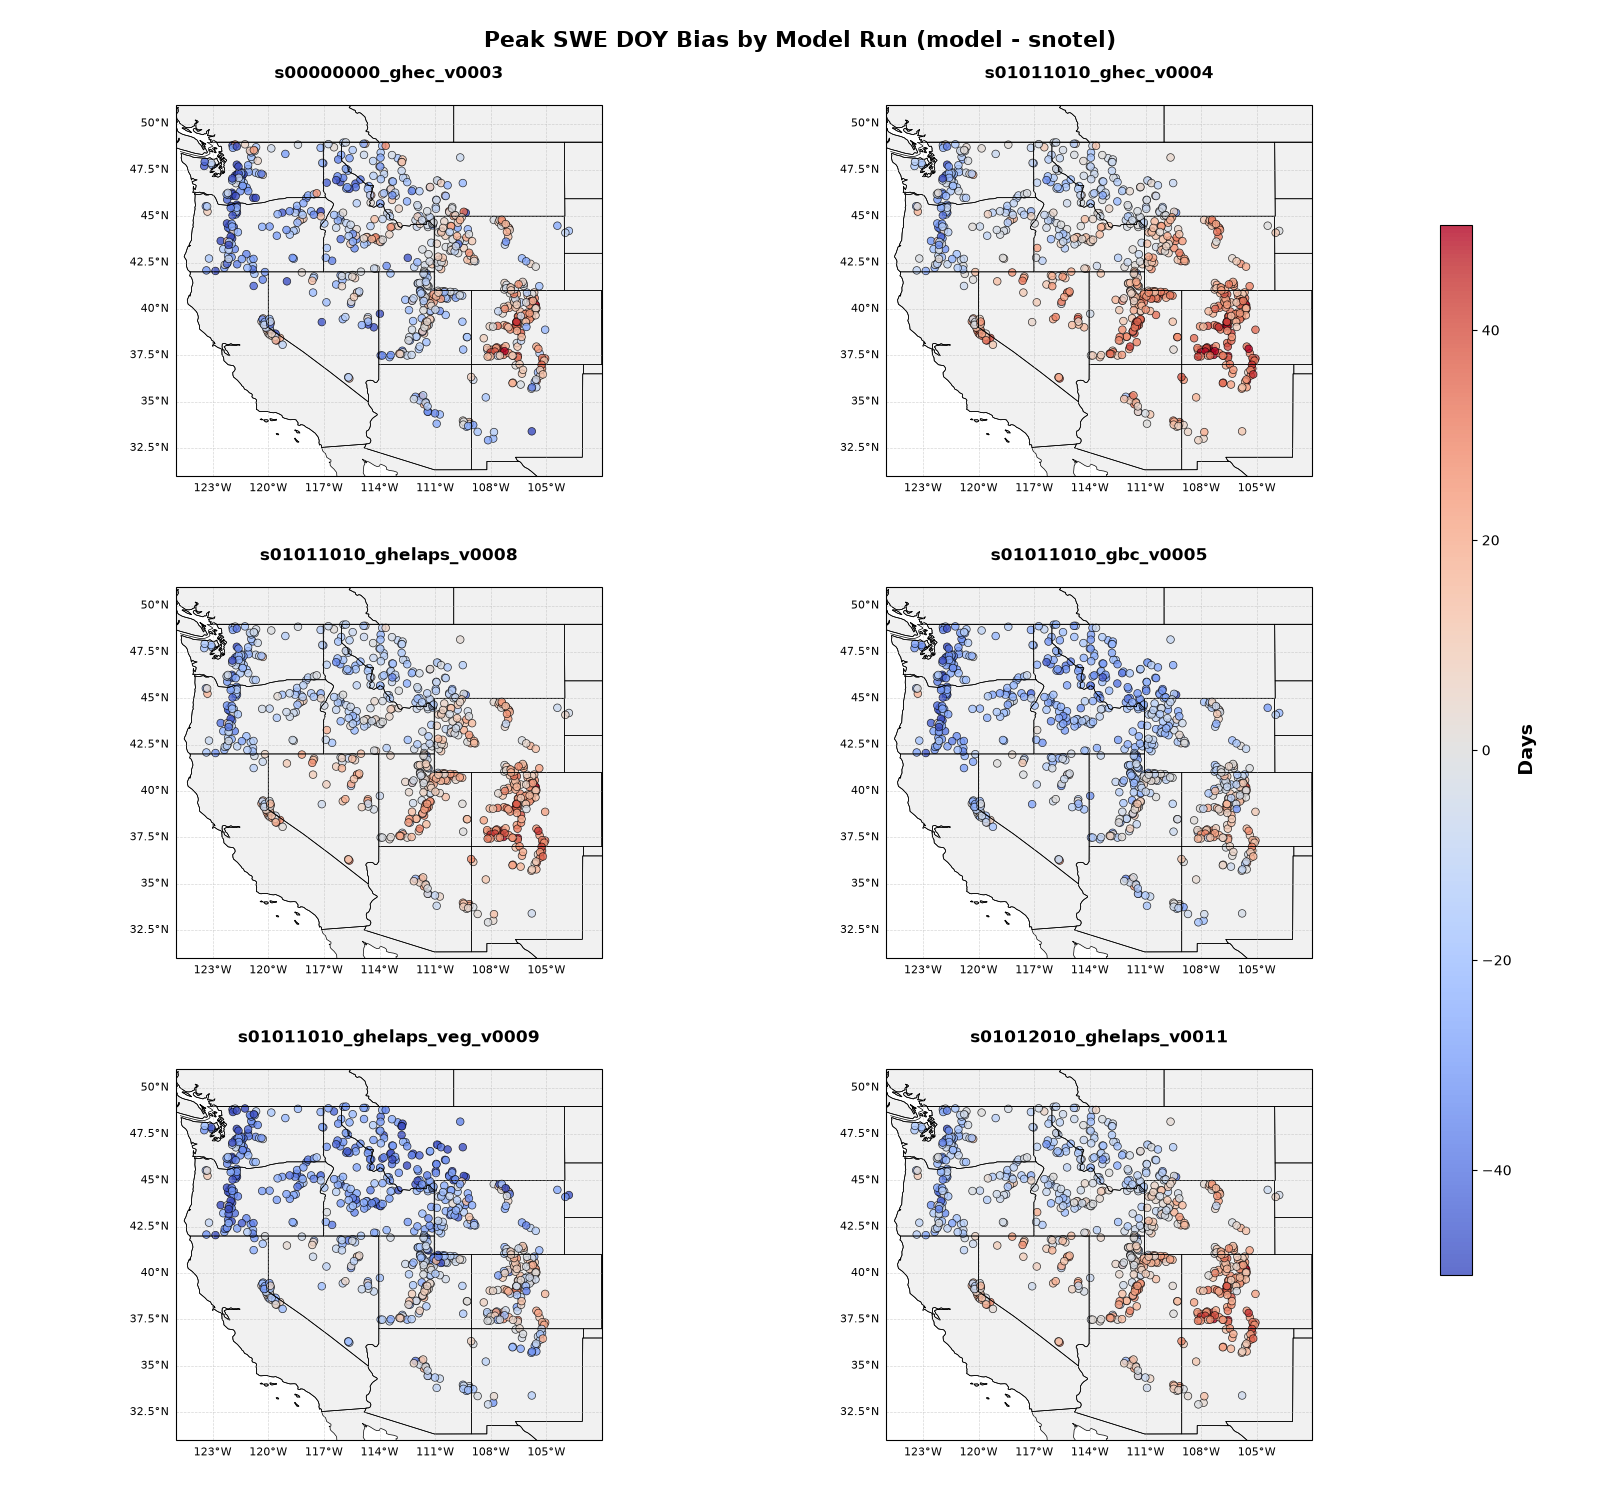

In [6]:
# Peak SWE DOY map - one subplot per model run
fig, axes = plt.subplots(3, 2, figsize=(16, 15), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(left=0.05, right=0.88, top=0.93, bottom=0.04, wspace=0.15, hspace=0.3)

for ax, (name, model_df) in zip(axes.flat, dfs.items()):
    model_peak_doy = model_df[['site', 'latitude', 'longitude', 'avg_peak_wydoy_snotel', 'avg_peak_wydoy_model']].copy()
    model_peak_doy['model_snotel_ddoy'] = model_peak_doy['avg_peak_wydoy_model'] - model_peak_doy['avg_peak_wydoy_snotel']

    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(model_peak_doy['longitude'], model_peak_doy['latitude'],
                         c=model_peak_doy['model_snotel_ddoy'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-50,
                         vmax=50,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=12, fontweight='bold', y=1.05)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

fig.suptitle('Peak SWE DOY Bias by Model Run (model - snotel)', fontsize=16, fontweight='bold')
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Days', fontsize=14, fontweight='bold')
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Unusual sites: shorter model season but later model peak
Identify sites where the model season is much shorter than observed (`model_snotel_ddays` very negative) while the model peak SWE date is much later than observed (`model_snotel_ddoy` very positive) — an unexpected combination. This looks at a single hardcoded model run (`MODEL_NAME` below), not all six model runs.

In [11]:
# Hardcoded model run for this diagnostic - change as needed
MODEL_NAME = 's01011010_ghelaps_v0008'
model_df = dfs[MODEL_NAME]

snow_days = model_df[['site', 'latitude', 'longitude', 'avg_snow_days_snotel', 'avg_snow_days_model']].copy()
snow_days['model_snotel_ddays'] = snow_days['avg_snow_days_model'] - snow_days['avg_snow_days_snotel']

peak_doy = model_df[['site', 'latitude', 'longitude', 'avg_peak_wydoy_snotel', 'avg_peak_wydoy_model']].copy()
peak_doy['model_snotel_ddoy'] = peak_doy['avg_peak_wydoy_model'] - peak_doy['avg_peak_wydoy_snotel']

# Combine the two diagnostics on site
unusual = snow_days[['site', 'latitude', 'longitude', 'model_snotel_ddays']].merge(
    peak_doy[['site', 'model_snotel_ddoy']], on='site'
)

# Score is only large when BOTH anomalies are present and severe:
# shorter model season (ddays << 0) and later model peak (ddoy >> 0).
# Using the min of the two "unusualness" directions means one large term
# can't inflate the score if the other condition isn't also met.
unusual['unusual_score'] = np.minimum(-unusual['model_snotel_ddays'], unusual['model_snotel_ddoy'])

print(f"Model: {MODEL_NAME}")
top5 = unusual.sort_values('unusual_score', ascending=False).head(5)
top5[['site', 'latitude', 'longitude', 'model_snotel_ddays', 'model_snotel_ddoy', 'unusual_score']]

Model: s01011010_ghelaps_v0008


,site,latitude,longitude,model_snotel_ddays,model_snotel_ddoy,unusual_score
133,Echo Lake,39.660000,-105.590000,-14.8,13.7,13.7
143,Reynolds Creek,43.288603,-116.843108,-13.4,18.7,13.4
53,Black Mountain,40.890000,-105.660000,-19.1,13.3,13.3
350,Elk Cabin,35.700000,-105.810000,-14.8,11.8,11.8
352,Snowslide Canyon,35.340000,-111.650000,-13.2,10.7,10.7


I took a look at Bar M and Horse Meadow to see what might cause the problematic behavior. Bar M looks like there is quite a bit of ephemeral snow so that might make the snow days calculation somewhat unusual. Horse Meadow doesn't look particularly strange, the later peak is visible, but snow days seem like they should be close.

### Melt season length

Melt season length = meltout DOY - peak DOY, using the `_all` (all model years, not snotel-matched) onset/peak/meltout columns since this compares model runs to each other rather than to snotel. Reference model is `s01011010_ghelaps_v0008`; each other model run's melt season length is differenced against it, site by site.

In [8]:
# Melt season length per model run
for name, d in dfs.items():
    d['melt_season_length'] = d['avg_meltout_wydoy_model_all'] - d['avg_peak_wydoy_model_all']

# Difference vs. the reference model, per site
baseline_name = 's01011010_ghelaps_v0008'
baseline = dfs[baseline_name][['site', 'melt_season_length']].rename(
    columns={'melt_season_length': 'melt_season_length_base'}
)

melt_season_diffs = {}
for name, d in dfs.items():
    if name == baseline_name:
        continue
    merged = d[['site', 'latitude', 'longitude', 'melt_season_length']].merge(baseline, on='site')
    merged['melt_season_diff'] = merged['melt_season_length'] - merged['melt_season_length_base']
    melt_season_diffs[name] = merged

melt_season_diffs['s00000000_ghec_v0003'].head()

,site,latitude,longitude,melt_season_length,melt_season_length_base,melt_season_diff
0,Forestdale Creek,38.682311,-119.960653,54.9,50.8,4.1
1,Horse Meadow,38.836411,-119.888317,48.7,39.5,9.2
2,Burnside Lake,38.719328,-119.895194,54.9,46.5,8.4
3,Summit Meadow,38.397400,-119.536217,41.9,39.8,2.1
4,Carson Pass,38.692667,-120.002128,56.4,48.9,7.5


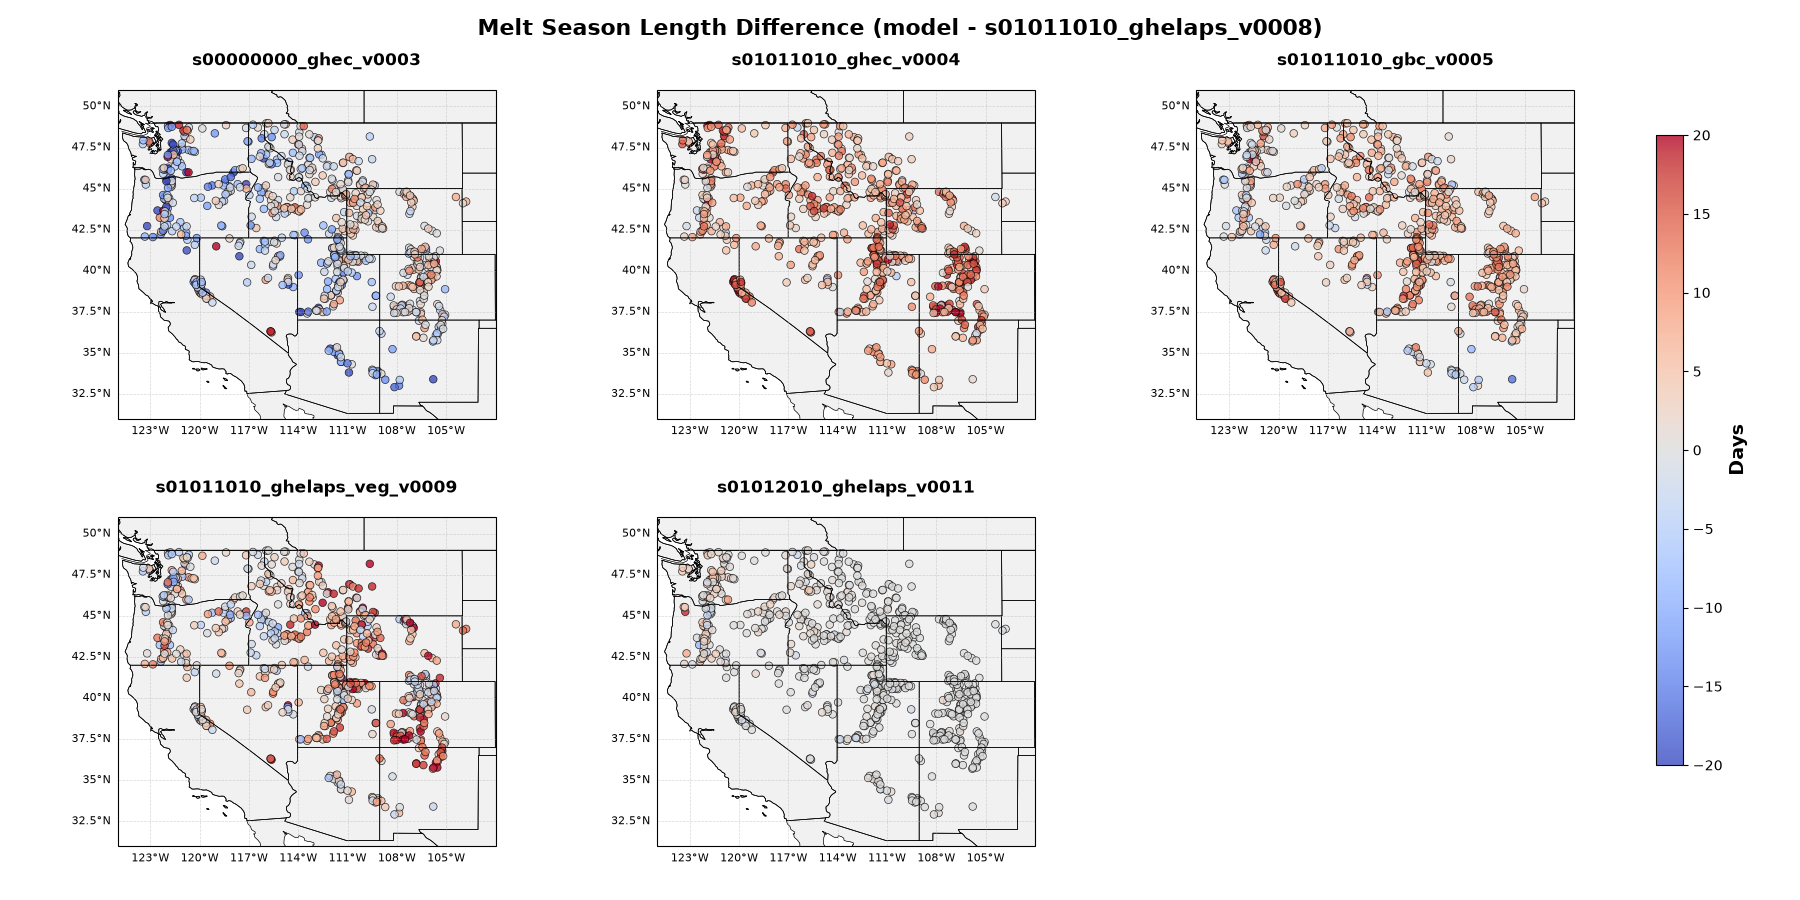

In [12]:
# Melt season length difference map - one subplot per comparison model run
fig, axes = plt.subplots(2, 3, figsize=(18, 9), subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(left=0.04, right=0.90, top=0.90, bottom=0.06, wspace=0.15, hspace=0.3)

for ax, (name, diff_df) in zip(axes.flat, melt_season_diffs.items()):
    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(diff_df['longitude'], diff_df['latitude'],
                         c=diff_df['melt_season_diff'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-20,
                         vmax=20,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    # y is set explicitly because cartopy's gridline labels break matplotlib's
    # automatic title-offset calculation (title silently fails to render otherwise)
    ax.set_title(name, fontsize=12, fontweight='bold', y=1.05)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

# Unused panel (5 comparison models in a 2x3 grid)
for ax in axes.flat[len(melt_season_diffs):]:
    fig.delaxes(ax)

fig.suptitle(f'Melt Season Length Difference (model - {baseline_name})', fontsize=16, fontweight='bold')
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Days', fontsize=14, fontweight='bold')